In [2]:
import matplotlib.pyplot as plt
from ultralytics import YOLO

In [8]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

print("XPU available:", hasattr(torch, "xpu") and torch.xpu.is_available())

if hasattr(torch, "xpu") and torch.xpu.is_available():
    print("XPU device:", torch.xpu.get_device_name(0))

PyTorch: 2.14.1+cu130
CUDA available: False
XPU available: False



image 1/1 /home/behnam/Repositories/image-processing/dataset_pass_segment/passport_scanned/passport_3.png: 896x1280 1 passport, 1 pass_id, 1 pic, 1 type, 1 country_code, 1 pass_no, 1 meli, 1 surname_en, 1 surname_fa, 1 name_en, 1 name_fa, 1 fname_en, 1 fname_fa, 1 bdate, 1 pdate, 1 sex, 1 shenasname, 1 dissuse, 1 dexpire, 1 mrz1, 1 mrz2, 90.0ms
Speed: 2.7ms preprocess, 90.0ms inference, 2.4ms postprocess per image at shape (1, 3, 896, 1280)


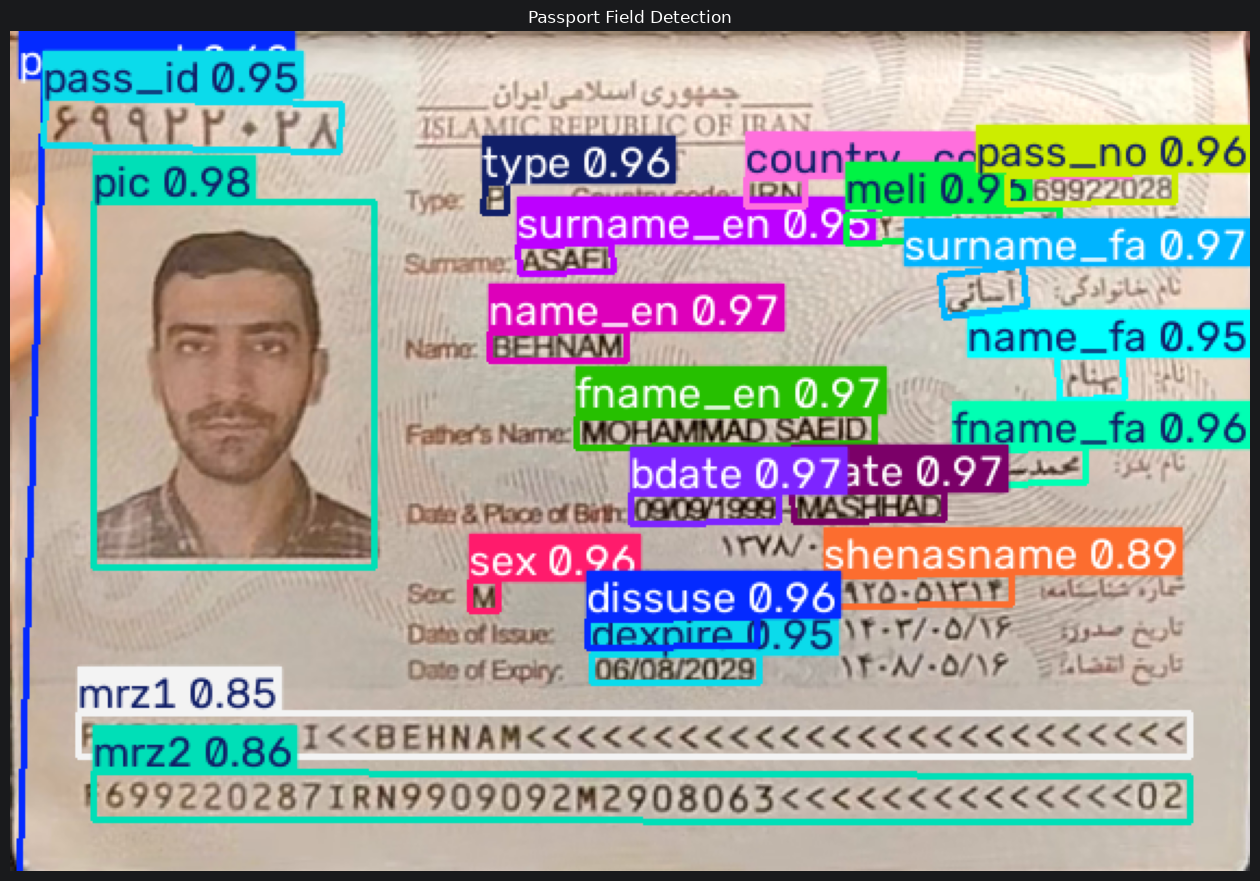

pic: 0.976 -> crops/0_pic_0.98.jpg


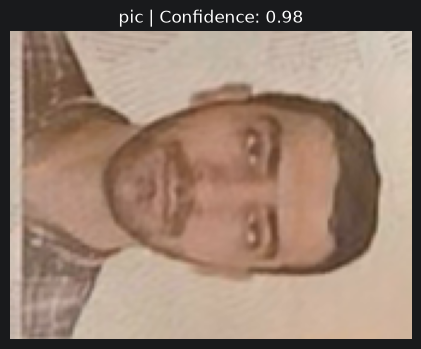

bdate: 0.973 -> crops/1_bdate_0.97.jpg


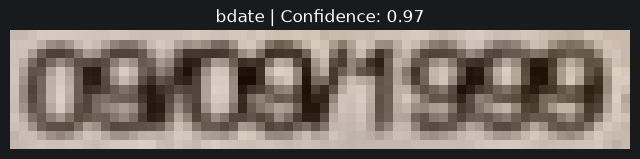

name_en: 0.971 -> crops/2_name_en_0.97.jpg


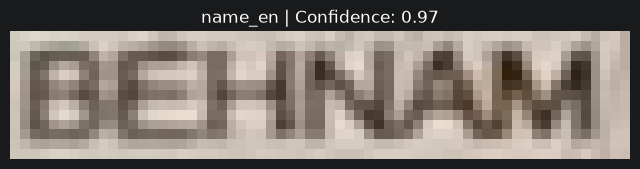

pdate: 0.970 -> crops/3_pdate_0.97.jpg


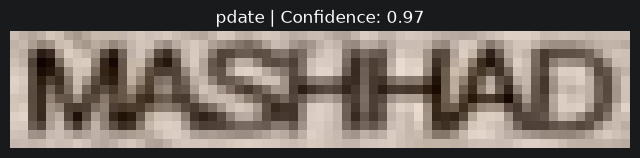

fname_en: 0.969 -> crops/4_fname_en_0.97.jpg


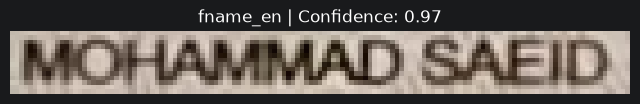

surname_fa: 0.966 -> crops/5_surname_fa_0.97.jpg


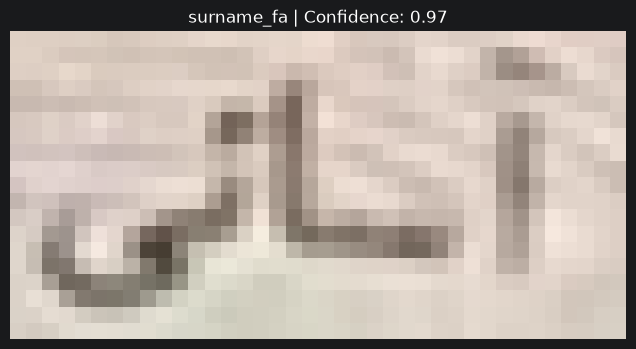

fname_fa: 0.961 -> crops/6_fname_fa_0.96.jpg


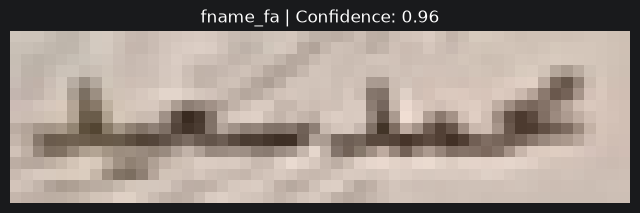

dissuse: 0.961 -> crops/7_dissuse_0.96.jpg


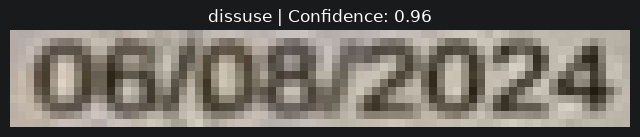

type: 0.960 -> crops/8_type_0.96.jpg


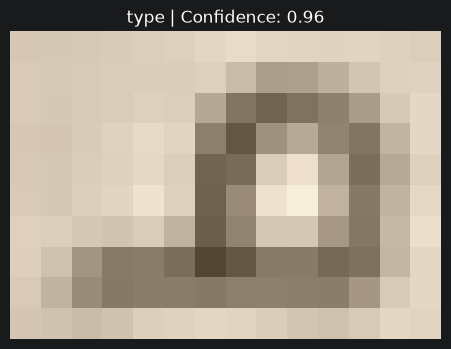

pass_no: 0.958 -> crops/9_pass_no_0.96.jpg


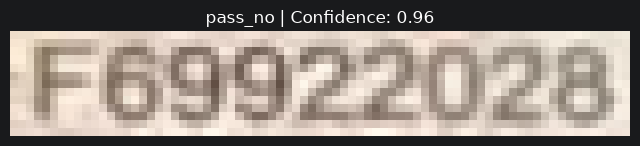

sex: 0.957 -> crops/10_sex_0.96.jpg


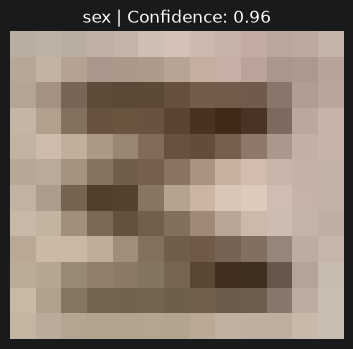

meli: 0.956 -> crops/11_meli_0.96.jpg


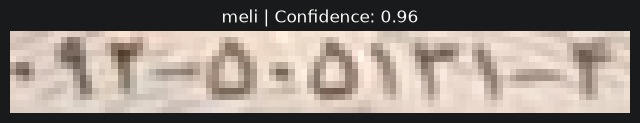

country_code: 0.956 -> crops/12_country_code_0.96.jpg


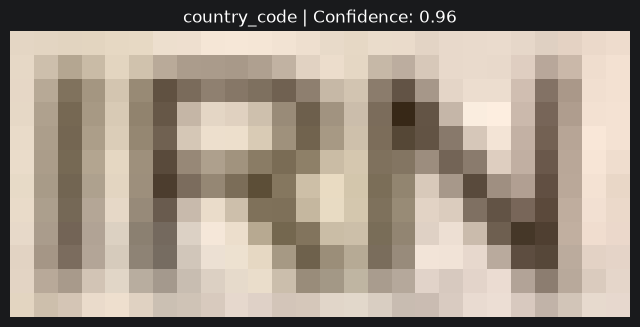

surname_en: 0.954 -> crops/13_surname_en_0.95.jpg


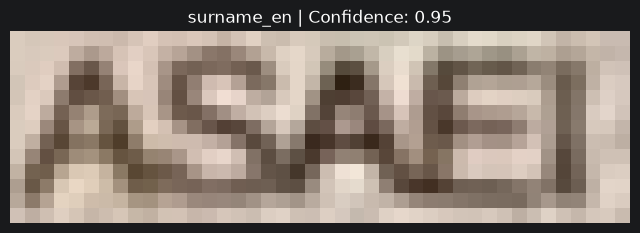

dexpire: 0.954 -> crops/14_dexpire_0.95.jpg


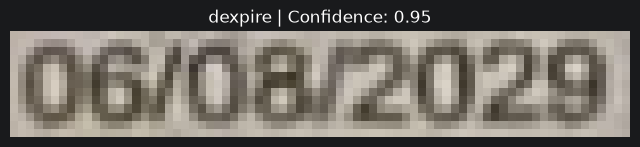

pass_id: 0.952 -> crops/15_pass_id_0.95.jpg


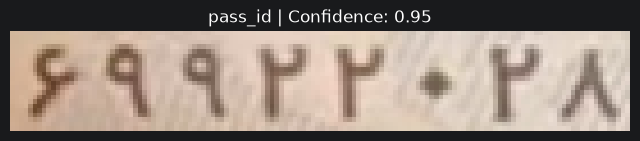

name_fa: 0.950 -> crops/16_name_fa_0.95.jpg


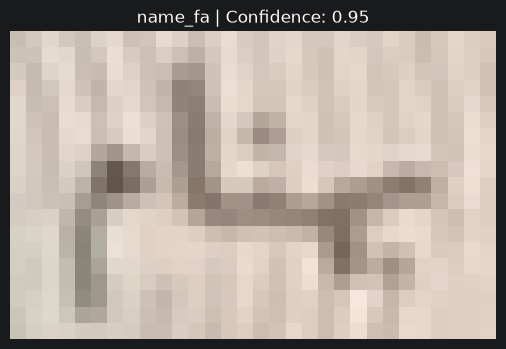

shenasname: 0.889 -> crops/17_shenasname_0.89.jpg


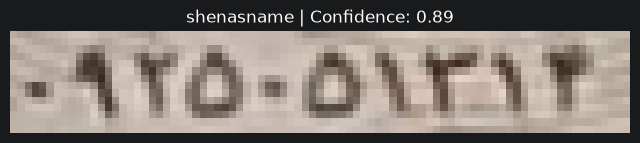

mrz2: 0.855 -> crops/18_mrz2_0.86.jpg


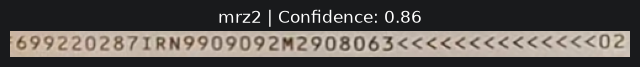

mrz1: 0.847 -> crops/19_mrz1_0.85.jpg


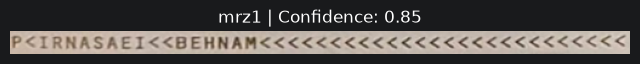

passport: 0.621 -> crops/20_passport_0.62.jpg


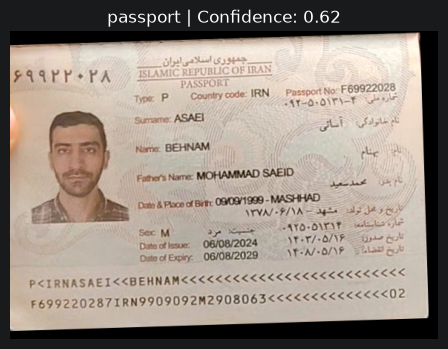

In [3]:
from ultralytics import YOLO
import cv2
import numpy as np
import matplotlib.pyplot as plt
import math
import os

# Load model
#
# runs/obb/runs/passport/yolo26m_obb_v2/weights/best.pt
# runs/obb/runs/passport/yolo26n_obb_strong_aug-2/weights/best.pt
# runs/obb/runs/passport/yolo26n_v3/weights/best.pt
# runs/obb/runs/passport/yolo26_s_v5/weights/best.pt
model = YOLO("runs/obb/runs/passport/yolo26_n_v1-2/weights/best.pt")

img_path = "dataset_pass_segment/passport_scanned/passport_3.png"

# Predict
results = model.predict(
    source=img_path,
    imgsz=1280,
    conf=0.5,
    iou=0.5,
    save=False,
    show_labels=True,
    show_conf=True,
    line_width=1
)

result = results[0]

# Read original image
image = cv2.imread(img_path)

# Display image with detected OBB boxes
annotated_image = result.plot()

plt.figure(figsize=(16, 12))
plt.imshow(cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB))
plt.title("Passport Field Detection")
plt.axis("off")
plt.show()


# Create output directory
output_dir = "crops"
os.makedirs(output_dir, exist_ok=True)


def crop_rotated_box(image, points):
    points = np.array(points, dtype=np.float32)

    width = int(max(
        np.linalg.norm(points[0] - points[1]),
        np.linalg.norm(points[2] - points[3])
    ))

    height = int(max(
        np.linalg.norm(points[0] - points[3]),
        np.linalg.norm(points[1] - points[2])
    ))

    if width <= 0 or height <= 0:
        return None

    destination = np.array([
        [0, 0],
        [width - 1, 0],
        [width - 1, height - 1],
        [0, height - 1]
    ], dtype=np.float32)

    matrix = cv2.getPerspectiveTransform(points, destination)

    cropped = cv2.warpPerspective(image, matrix, (width, height))

    # Always display horizontally
    if cropped.shape[0] > cropped.shape[1]:
        cropped = cv2.rotate(cropped, cv2.ROTATE_90_COUNTERCLOCKWISE)
        cropped = cv2.flip(cropped, 1)

    return cropped


# Extract OBB detections
if result.obb is not None:

    for index, box in enumerate(result.obb):

        class_id = int(box.cls[0])
        class_name = model.names[class_id]
        confidence = float(box.conf[0])

        # Get four corner points
        points = box.xyxyxyxy[0].cpu().numpy()

        # Crop field
        cropped = crop_rotated_box(image, points)

        if cropped is None:
            continue

        # Save crop
        filename = f"{index}_{class_name}_{confidence:.2f}.jpg"
        filepath = os.path.join(output_dir, filename)

        cv2.imwrite(filepath, cropped)

        print(f"{class_name}: {confidence:.3f} -> {filepath}")

        # Display crop
        plt.figure(figsize=(8, 4))
        plt.imshow(cv2.cvtColor(cropped, cv2.COLOR_BGR2RGB))
        plt.title(f"{class_name} | Confidence: {confidence:.2f}")
        plt.axis("off")
        plt.show()